# Task 24: Manual Decision Tree Feature Importance

## Objective
To implement a basic Decision Tree algorithm from scratch using Gini
impurity, identify the best feature splits, and rank features by their
importance without using scikit-learn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print("\nColumns:", list(df.columns))

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [2]:
target_column = "target"

if target_column not in df.columns:
    raise ValueError("Dataset must contain a 'target' column.")

data = df.dropna().reset_index(drop=True)

feature_columns = [
    col for col in data.select_dtypes(include=["number"]).columns
    if col != target_column
]

X = data[feature_columns].to_numpy(dtype=float)
y = data[target_column].to_numpy()

print("Features:", feature_columns)
print("Number of records:", len(y))
print("Target classes:", np.unique(y))

Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Number of records: 1025
Target classes: [0 1]


## Gini Impurity

Gini impurity measures how mixed the classes are within a node.

Gini = 1 - sum(p_i ** 2)

A good split reduces impurity. We calculate the weighted Gini impurity
of the child nodes and select the split with the greatest reduction.

In [4]:
def manual_gini(y_values):
    total = len(y_values)

    if total == 0:
        return 0

    counts = {}

    for label in y_values:
        counts[label] = counts.get(label, 0) + 1

    impurity = 1

    for count in counts.values():
        probability = count / total
        impurity -= probability ** 2

    return impurity

In [5]:
def find_best_split(X, y, feature_names):
    parent_gini = manual_gini(y)

    best_gain = 0
    best_split = None

    n_samples, n_features = X.shape

    for feature_index in range(n_features):
        values = sorted(set(X[:, feature_index]))

        # Candidate thresholds are midpoints between unique values
        thresholds = [
            (values[i] + values[i + 1]) / 2
            for i in range(len(values) - 1)
        ]

        for threshold in thresholds:
            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_gini = (
                len(y_left) / n_samples * manual_gini(y_left)
                + len(y_right) / n_samples * manual_gini(y_right)
            )

            gain = parent_gini - weighted_gini

            if gain > best_gain:
                best_gain = gain
                best_split = {
                    "feature": feature_names[feature_index],
                    "feature_index": feature_index,
                    "threshold": threshold,
                    "gain": gain,
                    "left_mask": left_mask,
                    "right_mask": right_mask
                }

    return best_split

In [6]:
def build_tree(X, y, feature_names, depth=0, max_depth=3, min_samples=10):
    # Stop if node is pure or stopping conditions are reached
    unique_classes = np.unique(y)

    if (
        len(unique_classes) == 1
        or depth >= max_depth
        or len(y) < min_samples
    ):
        values, counts = np.unique(y, return_counts=True)

        return {
            "leaf": True,
            "prediction": values[np.argmax(counts)],
            "samples": len(y)
        }

    split = find_best_split(X, y, feature_names)

    if split is None or split["gain"] <= 0:
        values, counts = np.unique(y, return_counts=True)

        return {
            "leaf": True,
            "prediction": values[np.argmax(counts)],
            "samples": len(y)
        }

    left_mask = split["left_mask"]
    right_mask = split["right_mask"]

    left_tree = build_tree(
        X[left_mask], y[left_mask], feature_names,
        depth + 1, max_depth, min_samples
    )

    right_tree = build_tree(
        X[right_mask], y[right_mask], feature_names,
        depth + 1, max_depth, min_samples
    )

    return {
        "leaf": False,
        "feature": split["feature"],
        "threshold": split["threshold"],
        "gain": split["gain"],
        "samples": len(y),
        "left": left_tree,
        "right": right_tree
    }

In [7]:
tree = build_tree(
    X,
    y,
    feature_columns,
    max_depth=3,
    min_samples=10
)

def print_tree(node, depth=0):
    indent = "  " * depth

    if node["leaf"]:
        print(
            f"{indent}Leaf: predict {node['prediction']} "
            f"(samples={node['samples']})"
        )
        return

    print(
        f"{indent}{node['feature']} <= {node['threshold']:.3f} "
        f"(Gini gain={node['gain']:.4f})"
    )

    print_tree(node["left"], depth + 1)
    print_tree(node["right"], depth + 1)

print_tree(tree)

cp <= 0.500 (Gini gain=0.1349)
  ca <= 0.500 (Gini gain=0.0931)
    thal <= 2.500 (Gini gain=0.1628)
      Leaf: predict 1 (samples=125)
      Leaf: predict 0 (samples=94)
    trestbps <= 109.000 (Gini gain=0.0116)
      Leaf: predict 0 (samples=17)
      Leaf: predict 0 (samples=261)
  age <= 56.500 (Gini gain=0.0461)
    oldpeak <= 3.550 (Gini gain=0.0352)
      Leaf: predict 1 (samples=313)
      Leaf: predict 0 (samples=7)
    sex <= 0.500 (Gini gain=0.0923)
      Leaf: predict 1 (samples=77)
      Leaf: predict 0 (samples=131)


In [8]:
importance = {feature: 0.0 for feature in feature_columns}

def collect_importance(node):
    if node["leaf"]:
        return

    # Weight each split's gain by the number of samples reaching the node
    weighted_gain = node["samples"] * node["gain"]

    importance[node["feature"]] += weighted_gain

    collect_importance(node["left"])
    collect_importance(node["right"])

collect_importance(tree)

total_importance = sum(importance.values())

if total_importance > 0:
    for feature in importance:
        importance[feature] /= total_importance

importance_df = pd.DataFrame([
    {"Feature": feature, "Importance": score}
    for feature, score in importance.items()
])

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print(importance_df.to_string(index=False))

 Feature  Importance
      cp    0.496976
      ca    0.166328
    thal    0.128138
     age    0.087401
     sex    0.069005
 oldpeak    0.040517
trestbps    0.011635
    chol    0.000000
     fbs    0.000000
   exang    0.000000
 thalach    0.000000
 restecg    0.000000
   slope    0.000000


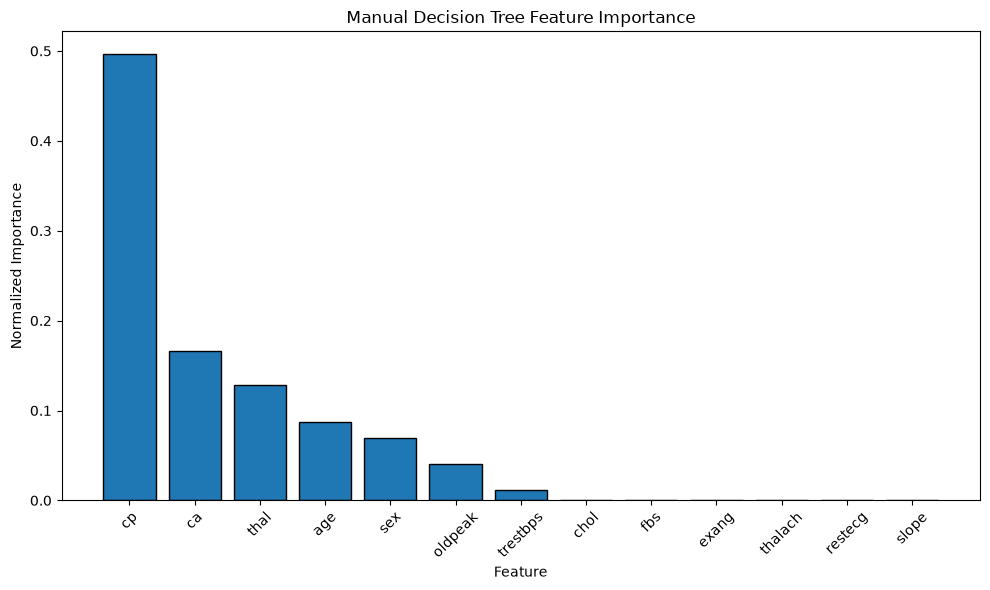

In [9]:
plt.figure(figsize=(10, 6))

plt.bar(
    importance_df["Feature"],
    importance_df["Importance"],
    edgecolor="black"
)

plt.xlabel("Feature")
plt.ylabel("Normalized Importance")
plt.title("Manual Decision Tree Feature Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Conclusion

A basic Decision Tree was implemented from scratch using manually
calculated Gini impurity and impurity reduction. The tree selected
feature thresholds recursively, and feature importance was estimated
by accumulating weighted impurity reductions across its splits.

The ranking depends on the data and tree settings, including maximum
depth and minimum samples per leaf. Features with zero importance were
not selected by this particular tree. This ranking should not be
interpreted as proof of causation or as a guarantee of predictive
performance.